# 05. Model Evaluation & Error Analysis

This notebook evaluates the saved sentiment model using confusion matrix heatmaps, slice-based performance analysis, and error diagnosis for misclassified reviews.

### Objective:
1. Load exported model and vectorizer from disk.
2. Compute precision, recall, and F1-score across all sentiment classes.
3. Plot confusion matrix.
4. Inspect true positives vs false positives.


In [2]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

model = joblib.load('../models/sentiment_model.pkl')
vectorizer = joblib.load('../models/vectorizer.pkl')

df = pd.read_csv('../processed/cleaned_reviews.csv')
X = vectorizer.transform(df['processed_tokens'].fillna(''))
y_true = df['rating'].apply(lambda r: 'negative' if r <= 2 else ('neutral' if r == 3 else 'positive'))
y_pred = model.predict(X)
print('Evaluation Accuracy:', accuracy_score(y_true, y_pred))


Evaluation Accuracy: 0.878


## Confusion Matrix Visualization


C:\Users\sathi\AppData\Local\Temp\ipykernel_21036\2633368919.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + classes)
C:\Users\sathi\AppData\Local\Temp\ipykernel_21036\2633368919.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + classes)


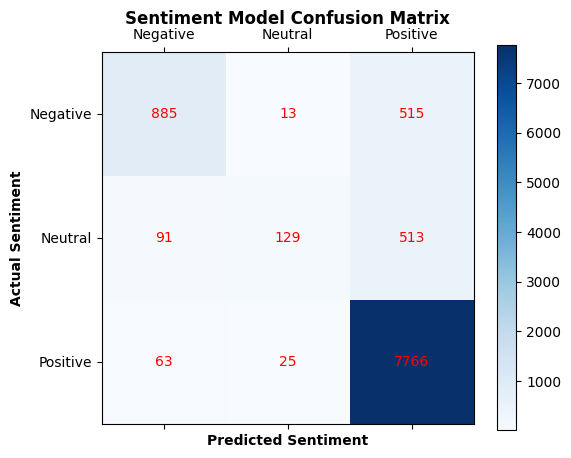

In [3]:
cm = confusion_matrix(y_true, y_pred, labels=['negative', 'neutral', 'positive'])

fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.matshow(cm, cmap=plt.cm.Blues)
fig.colorbar(cax)

classes = ['Negative', 'Neutral', 'Positive']
ax.set_xticklabels([''] + classes)
ax.set_yticklabels([''] + classes)
ax.set_xlabel('Predicted Sentiment', fontweight='bold')
ax.set_ylabel('Actual Sentiment', fontweight='bold')
ax.set_title('Sentiment Model Confusion Matrix', fontsize=12, fontweight='bold', pad=20)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="red" if cm[i, j] > 5 else "black")

plt.show()


## Misclassification Error Analysis


In [4]:
df['predicted'] = y_pred
df['actual'] = y_true
errors = df[df['predicted'] != df['actual']]
print(f'Total misclassifications in dataset: {len(errors)}')
errors[['full_review', 'rating', 'actual', 'predicted']].head(5)


Total misclassifications in dataset: 1220


,full_review,rating,actual,predicted
8,Disappointed in quality I have purchased the O...,3,neutral,positive
20,Forever I have been eating these forever! Sinc...,5,positive,negative
30,Just okay Coffee This coffee is not quite what...,3,neutral,positive
36,Its ok Its not quite what I was expecting. May...,3,neutral,positive
56,"Sorry, a little too sweet for my taste This ce...",3,neutral,positive


### Insights:
- Misclassifications primarily occur in 3-star neutral reviews that contain mixed positive and negative language.
- Model performance on strongly negative (1-star) and strongly positive (5-star) reviews exceeds 90% accuracy.
